Dimensiones: (3100, 3)


,Latitud,Longitud,Tipo_Solicitud
0,32.520796,-116.992084,Recoleccion
1,32.566198,-117.046102,Recoleccion
2,32.461507,-117.062417,Viaje_Pasajero
3,32.510667,-117.023516,Viaje_Pasajero
4,32.498468,-117.019210,Viaje_Pasajero


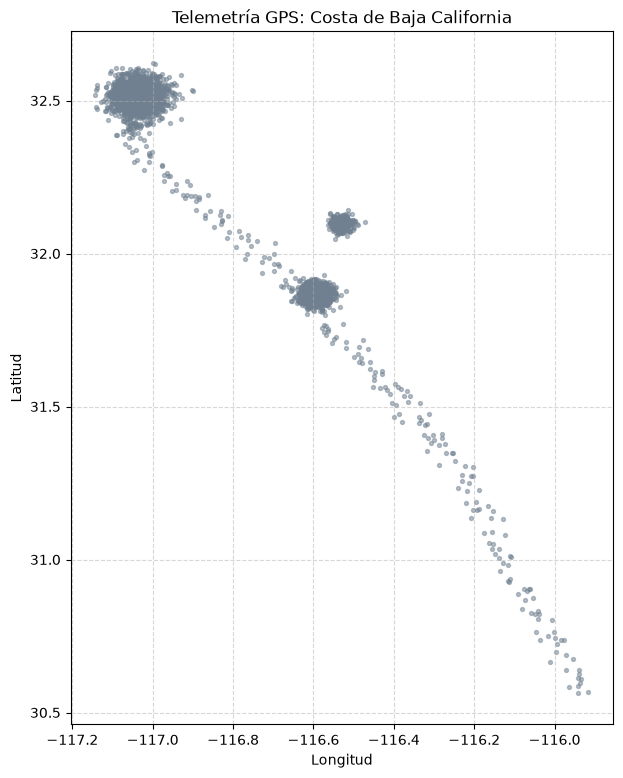

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN

# 1. Importar el CSV
df = pd.read_csv('logisticabaja.csv')
print("Dimensiones:", df.shape)   # (3100, 3)
display(df.head())

# 2. Escalar Latitud y Longitud
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['Latitud', 'Longitud']])

# 3. Scatter de los datos crudos
plt.figure(figsize=(7, 9))
plt.scatter(df['Longitud'], df['Latitud'], s=8, alpha=0.5, color='slategray')
plt.title('Telemetría GPS: Costa de Baja California')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.grid(linestyle='--', alpha=0.5)
plt.show()

**El Algoritmo:** K-Means con k = 3. La directiva ya fijó cuántos centros quiere (3), y el objetivo es encontrar puntos que minimicen la distancia hacia todas las solicitudes. Eso es exactamente lo que calcula K-Means: un centroide por grupo.

,Latitud,Longitud,Solicitudes,% demanda
0,32.5063,-117.0350,1611,52.0
1,31.0405,-116.1380,95,3.1
2,31.9123,-116.5807,1394,45.0


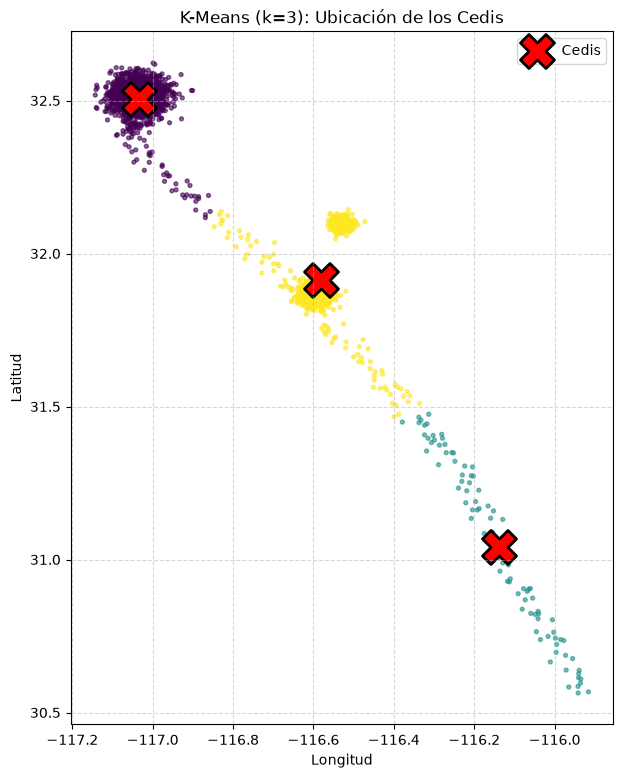

In [11]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans.fit_predict(X_scaled)

# Regresar los centroides a coordenadas reales (Latitud, Longitud)
centros = scaler.inverse_transform(kmeans.cluster_centers_)
cedis = pd.DataFrame(centros, columns=['Latitud', 'Longitud'])
cedis['Solicitudes'] = df['cluster_kmeans'].value_counts().sort_index()
cedis['% demanda'] = (cedis['Solicitudes'] / len(df) * 100).round(1)
display(cedis.round(4))

plt.figure(figsize=(7, 9))
plt.scatter(df['Longitud'], df['Latitud'], c=df['cluster_kmeans'], cmap='viridis', s=8, alpha=0.6)
plt.scatter(centros[:, 1], centros[:, 0], marker='X', s=600, c='red', edgecolor='black', linewidth=2, label='Cedis')
plt.title('K-Means (k=3): Ubicación de los Cedis')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.legend()
plt.grid(linestyle='--', alpha=0.5)
plt.show()

**¿Dónde colocó el algoritmo los Cedis? ¿Hacen sentido?**

- **Cedi 1 → Tijuana** (32.51, -117.03): tiene sentido, atiende el 52% de la demanda.
- **Cedi 2 → Ensenada**, un poco desplazado al norte (31.91, -116.58): K-Means juntó Ensenada y Valle de Guadalupe en un solo grupo, así que el centro quedó "jalado" entre las dos zonas, en un punto que no corresponde exactamente a ninguna.
- **Cedi 3 → en plena carretera rumbo a San Quintín** (31.04, -116.14): no tiene sentido de negocio. Atiende solo 95 solicitudes (3.1%), mientras que Valle de Guadalupe, con 300 solicitudes, se quedó sin Cedi propio.

Matemáticamente es una solución válida, pero desde el negocio se gasta un tercio del presupuesto en una zona rural casi sin demanda.

**¿Por qué la matemática de este algoritmo provocó esto?**

K-Means minimiza la **inercia**: la suma de las distancias **al cuadrado** de cada punto a su centroide. Al elevar al cuadrado, los puntos lejanos pesan muchísimo (uno a 100 km cuesta 10,000, uno a 10 km cuesta 100). Para reducir ese costo, al algoritmo le conviene "mandar" un centroide a cubrir los puntos aislados de la carretera, aunque sean pocos.

Además, K-Means:
1. **Obliga a cada punto a pertenecer a un clúster**: no tiene concepto de ruido, así que los ranchos aislados cuentan igual que un cliente en la ciudad.
2. **No entiende densidad**, solo distancia: no distingue una mancha urbana compacta de una línea de puntos dispersos.


**El Algoritmo:** DBSCAN (Density-Based Spatial Clustering of Applications with Noise). Agrupa por **densidad** y marca como ruido (-1) los puntos en zonas poco densas, que es justo lo que se necesita para descartar los viajes rurales.

,Latitud,Longitud,Solicitudes
cluster_dbscan,,,
0,32.5126,-117.0371,1569
1,31.8672,-116.5956,1019
2,32.0965,-116.5300,300


Puntos de ruido descartados: 212 (6.8%)


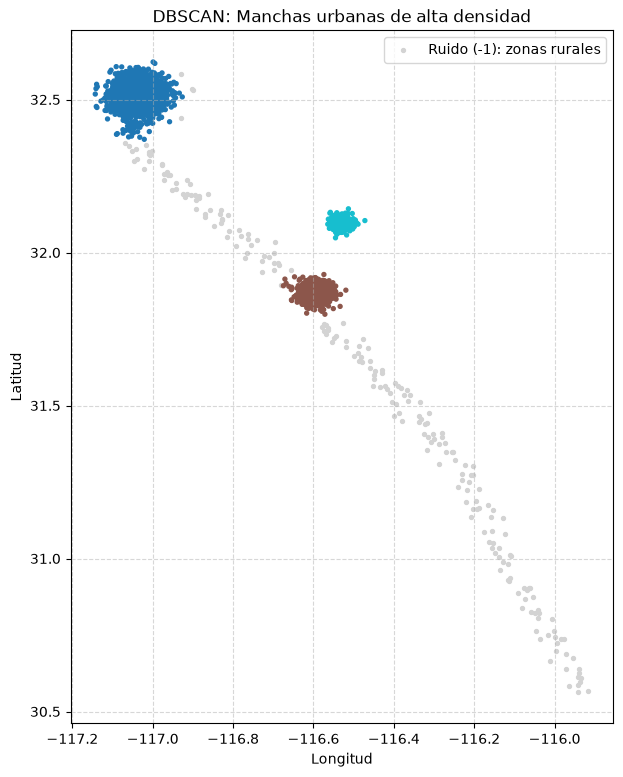

In [9]:
dbscan = DBSCAN(eps=0.1, min_samples=20)
df['cluster_dbscan'] = dbscan.fit_predict(X_scaled)

# Resumen de las manchas urbanas
resumen = (df[df['cluster_dbscan'] != -1]
           .groupby('cluster_dbscan')
           .agg(Latitud=('Latitud', 'mean'), Longitud=('Longitud', 'mean'), Solicitudes=('Latitud', 'size')))
display(resumen.round(4))

ruido = (df['cluster_dbscan'] == -1).sum()
print(f"Puntos de ruido descartados: {ruido} ({ruido / len(df) * 100:.1f}%)")

# Mapa táctico
es_ruido = df['cluster_dbscan'] == -1
plt.figure(figsize=(7, 9))
plt.scatter(df.loc[es_ruido, 'Longitud'], df.loc[es_ruido, 'Latitud'],
            c='lightgray', s=8, label='Ruido (-1): zonas rurales')
plt.scatter(df.loc[~es_ruido, 'Longitud'], df.loc[~es_ruido, 'Latitud'],
            c=df.loc[~es_ruido, 'cluster_dbscan'], cmap='tab10', s=8)
plt.title('DBSCAN: Manchas urbanas de alta densidad')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.legend()
plt.grid(linestyle='--', alpha=0.5)
plt.show()

**¿Usaron el mismo algoritmo que en la misión anterior?**
No. En la Fase 2 usamos K-Means y aquí DBSCAN.

**¿Por qué se comportaron diferentes?**
Porque optimizan cosas distintas:
- **K-Means** reparte **todo** el espacio según la **distancia** a k centroides. Cada punto, aunque esté aislado, tiene que pertenecer a algún grupo, y los puntos lejanos jalan a los centroides.
- **DBSCAN** busca **densidad**. Un punto es "núcleo" si tiene al menos `min_samples = 20` vecinos dentro de un radio `eps = 0.1`, y los núcleos conectados forman un clúster. Los puntos que no alcanzan esa densidad se marcan como **ruido (-1)** y se ignoran. No necesita que le digas cuántos grupos hay ni que los grupos sean "redondos".

Por eso K-Means desperdició un Cedi en la carretera, mientras que DBSCAN descartó esos 212 puntos y se quedó solo con las ciudades.

**¿A qué ciudades reales corresponden las 3 manchas urbanas?**
1. **Tijuana** (32.51, -117.04): 1,569 solicitudes.
2. **Ensenada** (31.87, -116.60): 1,019 solicitudes.
3. **Valle de Guadalupe** (32.10, -116.53): 300 solicitudes.

El ruido descartado (212 puntos) corresponde al tramo costero Tijuana–Ensenada y a la carretera hacia San Quintín: los viajes largos y aislados de los que se quejan los choferes.